# Lecture 18 - Natural Language Processing

[![View notebook on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.ipynb)
[![View on Website](https://img.shields.io/static/v1.svg?logo=quarto&label=Web&message=View%20on%20Website&color=blue)](https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.html)

<a id='top'></a>

- [18.1 Introduction to NLP](#18.1-introduction-to-nlp)
- [18.2 Preprocessing Text Data](#18.2-preprocessing-text-data)
    - [18.2.1 Text Standardization](#18.2.1-text-standardization)
    - [18.2.2 Tokenization](#18.2.2-tokenization)
- [18.3 Introduction to Hugging Face](#18.3-introduction-to-hugging-face)
- [18.4 Tokenizers](#18.4-tokenizers)
    - [18.4.1 Tokenizing Text](#18.4.1-tokenizing-text)
    - [18.4.2 Special Tokens and Subwords](#18.4.2-special-tokens-and-subwords)
    - [18.4.3 Padding and Truncation](#18.4.3-padding-and-truncation)
- [18.5 Datasets](#18.5-datasets)
    - [18.5.1 Loading the IMDB Reviews Dataset](#18.5.1-loading-the-imdb-reviews-dataset)
    - [18.5.2 Applying a Tokenizer to a Dataset](#18.5.2-applying-a-tokenizer-to-a-dataset)
- [18.6 Representation of Groups of Words](#18.6-representation-of-groups-of-words)
    - [18.6.1 Bag-of-Words Models](#18.6.1-bag-of-words-models)
- [18.7 Sequence Models Approach](#18.7-sequence-models-approach)
    - [18.7.1 One-Hot Word Vector Representation](#18.7.1-one-hot-word-vector-representation)
    - [18.7.2 Word Embeddings](#18.7.2-word-embeddings)
- [18.8 Models](#18.8-models)
    - [18.8.1 Importing a Pretrained Model](#18.8.1-importing-a-pretrained-model)
    - [18.8.2 Fine-tuning a Pretrained Model](#18.8.2-fine-tuning-a-pretrained-model)
    - [18.8.3 Generation Strategies](#18.8.3-generation-strategies)
- [18.9 NLP Pipelines](#18.9-nlp-pipelines)
    - [18.9.1 Sentiment Analysis](#18.9.1-sentiment-analysis)
    - [18.9.2 Question Answering](#18.9.2-question-answering)
    - [18.9.3 Machine Translation](#18.9.3-machine-translation)
    - [18.9.4 Text Summarization](#18.9.4-text-summarization)
    - [18.9.5 Text Generation](#18.9.5-text-generation)
    - [18.9.6 Named Entity Recognition](#18.9.6-named-entity-recognition)
    - [18.9.7 Zero-shot Classification](#18.9.7-zero-shot-classification)
    - [18.9.8 Mask Filling](#18.9.8-mask-filling)
- [Appendix: Sentiment Classification with an Embedding Model](#appendix:-sentiment-classification-with-an-embedding-model)
- [References](#references)

<a id="18.1-introduction-to-nlp"></a>

## 18.1 Introduction to NLP

**Natural Language Processing (NLP)** is a branch of Computer Science (and more broadly, a branch of Artificial Intelligence) that is concerned with providing computers with the ability to understand texts and human language.

Common tasks in NLP include:

- *Text classification* — assign a class label to text based on the topic discussed in the text, e.g., sentiment analysis (positive or negative movie review), spam detection, content filtering (detect abusive content).
- *Text summarization/reading comprehension* — summarize a long input document with a shorter text.
- *Speech recognition* — convert spoken language to text.
- *Machine translation* — convert text in a source language to a target language.
- *Part of Speech (PoS) tagging* — mark up words in text as nouns, verbs, adverbs, etc.
- *Question answering* — output an answer to an input question.
- *Dialog generation* — generate the next reply in a conversation given the history of the conversation.
- *Text generation* — generate text to complete the sentence or to complete the paragraph.

Until recently, each of these tasks was solved with a separate, specialized model trained on task-specific data. Large Language Models (LLMs) have changed this: a single pretrained model can perform most of the above tasks, either directly from a text prompt or after a fine-tuning on a small dataset.

In this lecture, we will first cover the basic concepts for converting text into a numerical form that Machine Learning models can process. Afterward, we will introduce the Hugging Face platform, and we will use it to tokenize text, load datasets, fine-tune a pretrained model, generate text, and build pipelines for NLP tasks.

<a id="18.2-preprocessing-text-data"></a>

## 18.2 Preprocessing Text Data

Before text data can be processed by NLP models, it must first be converted into a numerical representation.

Converting text into numerical form typically involves the following steps:

- *Standardization* - remove punctuation, convert the text to lowercase letters.
- *Tokenization* - break the text into smaller units called tokens (e.g., individual words, individual characters, several consecutive words, etc.).
- *Indexing* - assign a unique numerical index to each token in the training set (i.e., build a vocabulary).
- *Embedding* - (used in more recent models) assign a numerical vector to each token that represents it in a continuous vector space. Examples include one-hot encoding and word embeddings.

Note that differently from conventional NLP models that employ the text preprocessing steps listed above, LLMs typically apply minimal text processing and standardization, such as removing irregular spacing in text, removing non-textual content (e.g., code, HTML tags), and removing unsafe or low-quality text content. Therefore, text preprocessing for LLM training focuses mainly on data cleanliness, and not on linguistic simplification.

<a id="18.2.1-text-standardization"></a>

### 18.2.1 Text Standardization
**Text standardization** usually includes several steps, which depend on the specific application. The steps involve:

- Remove punctuation marks (such as comma, period) or non-alphabetic characters (@, #, {, ]).
- Change all words to lowercase letters, since ML models should consider *Text* and *text* as the same word.

Some NLP tasks apply additional steps, such as:

- Correct spelling errors, or replace abbreviations with full words.
- Remove stop words, such as *for*, *the*, *is*, *to*, *some*, etc.; if the task is text classification, these words are not relevant to the meaning of the text.
- Apply stemming and lemmatization, which transform words to their base form, such as changing the word *driving* to *drive*, or *grilled* to *grill* since they have a common root.

Applying text standardization is helpful for training ML models, for example, because the models do not need to consider *Text* and *text* as two different words, which reduces the requirements for large training datasets. However, depending on the application, text standardization may remove information that can be important for some tasks, and this should always be considered when performing text preprocessing.

<a id="18.2.2-tokenization"></a>

### 18.2.2 Tokenization
**Tokenization** is breaking up a sequence of text into individual units called *tokens*.

Tokenization can be performed at different levels:

- *Character-level tokenization* - the text is divided into individual characters, and each character is a token, including letters, digits, punctuation marks, and symbols. One disadvantage of this type of tokenization is that anagrams (words with same letters in different order, such as *silent* and *listen*) can have the same numerical encoding, which can affect the performance of ML models. As well as, character-level tokenization does not capture semantic meaning of words as effectively as word-level tokens. Consequently, it is not widely used in practice.
- *Word-level tokenization* - each word in the text is a token. This type of tokenization provides a natural representation of input text with the words as building blocks of language, and it is commonly used.
- *Subword-level tokenization* - the words are divided into smaller units (e.g., tokenizing the word "unhappiness" into two tokens "un" + "happiness"). This type of tokenization is very common in recent Large Language Models. Also, in some languages with complex word structures, subword-level tokenization is the most suitable.
- *N-gram tokenization* - N consecutive words represent a token. For instance, N-grams consisting of two adjacent words are called bigrams, or three words constitute a trigram, etc. N-gram tokens preserve the word order and can potentially capture more information in the text. For instance, for spam filtering using  bigram tokens such as *mailing list* or *bank account* may provide more helpful information than using word-level tokens.

For some NLP tasks, tokenization can also be performed at other levels of text. An example is sentence-level tokenization for the task of document segmentation in sentences.

An example of text standardization, word-level tokenization, and indexing is shown in the next figure.

<img src="images/tokenization.png" width="500">

*Figure: Text standardization, word-level tokenization, and indexing.*

Note also that in modern LLMs, subword tokenizers are not defined by hand, but are learned from a large text corpus. The most common algorithms are *Byte-Pair Encoding (BPE)* used by the GPT family of models, Llama, and most recent LLMs, *WordPiece* used by BERT, and *Unigram/SentencePiece* used by T5 and multilingual models. These tokenizers start from a vocabulary of individual characters (or bytes) and repeatedly merge the most frequent adjacent pairs of tokens, until the vocabulary reaches a predefined size, which is typically between 30,000 and 150,000 tokens. As a result, frequent words end up as single tokens, while rare words are split into several subword tokens, so that any text can be encoded without out-of-vocabulary words. We will work with such tokenizers in Section 18.4.

<a id="18.3-introduction-to-hugging-face"></a>

## 18.3 Introduction to Hugging Face

**Hugging Face** ([link](https://huggingface.co/)) is a platform for Machine Learning and AI created in 2016, with the aim to "build, train, and deploy state of the art models powered by the reference open source in machine learning". Since then, Hugging Face has established itself as the main source for NLP and other Machine Learning tasks, providing open access to over 2 million pre-trained models, datasets, and pertinent tools and resources. Hugging Face focuses on community-building around open-source machine learning tools and data. They also developed several [courses](https://huggingface.co/learn) on how to use their libraries for various tasks. Also note that while open access is provided to the core NLP libraries, Hugging Face also offers paid options for enterprise features, hosted inference endpoints, and the AutoTrain service for no-code model training.

The core Hugging Face libraries include Transformer models, Tokenizers, Datasets, and Accelerate. Accelerate library enables distributed training with hardware acceleration devices, such as using multiple GPUs, or cloud accelerators with TPUs. In addition to these core libraries, Hugging Face provides various community resources, which include a platform for sharing models, code versioning, Spaces allow sharing apps developed with Hugging Face libraries and browsing apps created by others, etc.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/images/hf_libraries.png" width="400">

*Figure: Hugging Face libraries.*

The key characteristics of these libraries include:

- Ease of use and simplicity, where downloading and using state-of-the-art NLP models can be done with a few lines of code.
- Flexibility, since all models in the Transformers library are implemented as PyTorch `nn.Module` objects (earlier versions of the library also provided TensorFlow and JAX implementations for some models, but recent versions focus on PyTorch only).

<a id="18.4-tokenizers"></a>

## 18.4 Tokenizers

Hugging Face provides a **Tokenizers** library for converting raw text into sequences of tokens. The provided tokenizer functions perform text standardization, tokenization, and indexing.

When we use a pretrained model from Hugging Face, our text data needs to be preprocessed in the same way as the training data used with the model. Therefore, we will need to download the tokenizer for that specific model. Access to pretrained models is provided through the `transformers` library and the [Hugging Face Hub](https://huggingface.co/models).

Let's consider the model `"distilbert-base-uncased"`, which is a version of the BERT transformer model, which takes case-insensitive English text as input data. To use the the tokenizer for this model, we will first import it from the `transformers` package, and we will download it from the Hugging Face Hub with the `AutoTokenizer` class and its method `from_pretrained()`. The argument `model_ckpt` is short for model checkpoint, and it stores the name of the pretrained model.

The `AutoTokenizer` is convenient to use since we don't need to manually download and manage the tokenizer files. Alternatively, we can also specify the tokenizer class for the model that we wish to use. For instance, for the BERT model, Hugging Face has a `BertTokenizer` that can be directly imported from the `transformers` package.

In [1]:
from transformers import AutoTokenizer

model_ckpt = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

The code loads the tokenizer associated with that model, including its vocabulary and tokenization and configuration settings. Note that the code loads the tokenizer, not the weights for model "distilbert-base-uncased".

<a id="18.4.1-tokenizing-text"></a>

### 18.4.1 Tokenizing Text

Let's now use the `tokenizer` to convert a text sentence into a sequence of integers and examine the output. The example in the next cell tokenizes the sentence "Tokenizing text is easy."

The output of the tokenizer is a dictionary consisting of the following key-value pairs:

- `input_ids`, a list of integers, where each integer represents a token. The indexing is based on the vocabulary of the training data that was used to train the model `"distilbert-base-uncased"`. The sequence also includes special tokens, as explained in the next section.
- `token_type_ids` (returned by some tokenizers, depending on the model and the library version), a list of 0's and 1's that distinguishes between inputs consisting of a pair of sentences (e.g., a question and a context). For a single sentence, all values are 0's and it can be ignored.
- `attention_mask`, a list of 1's or 0's, to indicate padding of the text sequence. A value of 1 represents a valid token, while 0 represents a padding token. In this example, the sentence contains no padding, so all values in the attention mask are 1. The attention mask allows the Transformer models to ignore padding tokens.

In [2]:
output_tokens_1 = tokenizer('Tokenizing text is easy.')
print(output_tokens_1)

{'input_ids': [101, 19204, 6026, 3793, 2003, 3733, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


<a id="18.4.2-special-tokens-and-subwords"></a>

### 18.4.2 Special Tokens and Subwords

Note that the above output has 8 tokens, although the input sentence has 4 words and the period mark. To understand better how the tokenization was performed, in the next cell we used the method `convert_ids_to_tokens()` to obtain the text for each integer value in `input_ids`. Now we can see that the tokenizer places special tokens at the beginning and end of each sequence. `[CLS]` is placed at the beginning (it stands for Classification), and `[SEP]` is placed at the end of the sequence (it stands for Separate).

Also note that the gerund verb "tokenizing" is split into `'token'` and `'##izing'`. Using two tokens for the word allows to work with smaller vocabularies. I.e., instead of considering `token` and `tokenizing` as two different words, by splitting the word into the root `token` and the suffix `izing`, the model will use two tokens that have a distinct semantic meaning. This approach of decomposing long words into subwords is especially efficient with some languages where one can form very long words by chaining simple subwords.

In [3]:
tokenizer.convert_ids_to_tokens(output_tokens_1.input_ids)

['[CLS]', 'token', '##izing', 'text', 'is', 'easy', '.', '[SEP]']

Most tokenizers in Hugging Face assign integers for the special tokens between 100 and 103, and 0 is commonly used for the padding token.

These special tokens include:

- \[PAD\], padding.
- \[UNK\], unknown token.
- \[CLS\], sequence beginning.
- \[SEP\], sequence end.
- \[MASK\], masked tokens.

In [4]:
tokenizer.convert_ids_to_tokens([0, 100, 101, 102, 103])

['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]']

Another simple example is provided next. We can see that the word `'Transformer'` is tokenized as `'transform'` + `'##er'`.

In [5]:
output_tokens_2 = tokenizer('Using a Transformer network in Hugging Face is simple')
print(output_tokens_2)

{'input_ids': [101, 2478, 1037, 10938, 2121, 2897, 1999, 17662, 2227, 2003, 3722, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
tokenizer.convert_ids_to_tokens(output_tokens_2.input_ids)

['[CLS]',
 'using',
 'a',
 'transform',
 '##er',
 'network',
 'in',
 'hugging',
 'face',
 'is',
 'simple',
 '[SEP]']

The reverse operation of converting a sequence of token `input_ids` back into text is performed with the `decode()` method. Note that the decoded text is lowercase, since this tokenizer belongs to an *uncased* model, i.e., "distilbert-base-uncased".

In [6]:
tokenizer.decode(output_tokens_2.input_ids)

'[CLS] using a transformer network in hugging face is simple [SEP]'

The argument `skip_special_tokens=True` removes the special tokens from the output.

In [7]:
tokenizer.decode(output_tokens_2.input_ids, skip_special_tokens=True)

'using a transformer network in hugging face is simple'

The tokenizer also has a `vocab_size` attribute, which is the number of tokens in its vocabulary. The vocabulary for the "distilbert-base-uncased" model has 30,522 tokens.

In [8]:
tokenizer.vocab_size

30522

<a id="18.4.3-padding-and-truncation"></a>

### 18.4.3 Padding and Truncation

Tokenizers can be applied to multiple text sequences. The argument `padding=True` in the next example is used to pad the sequences to the longest sequence. Note below that 0's are added to pad the second sentence.

In [9]:
text_3 =  ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]

output_tokens_3 = tokenizer(text_3, padding=True)

In [10]:
print(output_tokens_3)

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], [101, 1045, 5223, 2023, 2061, 2172, 999, 102, 0, 0, 0, 0, 0, 0, 0, 0]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]]}


The output is more readable if we print it line by line.

In [11]:
print("Input IDs")
for item in output_tokens_3.input_ids:
    print(item)

print("Attention Mask")
for item in output_tokens_3.attention_mask:
    print(item)

Input IDs
[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102]
[101, 1045, 5223, 2023, 2061, 2172, 999, 102, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]


Note also that each sequence of tokens begins with 101 (`'[CLS]'`) and ends with 102 (`'[SEP]'`), and the `attention mask` contains 0s for the padding tokens to indicate that they don't need to be processed by the model.

If `max_length` is provided together with `truncation=True`, the tokenizer will truncate longer sequences to the specified length (including the special tokens), as in the example in the next cell. Every model has a maximum sequence length that it can process (512 tokens for BERT and DistilBERT), so truncation is needed for long documents. Padding and truncation together produce batches of sequences with the same length that can be passed to a model for training or prediction.

In [12]:
output_tokens_4 = tokenizer(text_3, padding=False, truncation=True, max_length=10)

print("Input IDs")
for item in output_tokens_4.input_ids:
    print(item)

print("Attention Mask")
for item in output_tokens_4.attention_mask:
    print(item)

Input IDs
[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 102]
[101, 1045, 5223, 2023, 2061, 2172, 999, 102]
Attention Mask
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[1, 1, 1, 1, 1, 1, 1, 1]


Finally, the tokenizer can return PyTorch tensors instead of Python lists with the argument `return_tensors="pt"`, which is what we need for passing the inputs to a model. This requires `padding=True`, so that all sequences in the batch have the same length.

In [13]:
output_tokens_5 = tokenizer(text_3, padding=True, return_tensors="pt")

print(output_tokens_5["input_ids"])
print(output_tokens_5["input_ids"].shape)

tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  2023,  2061,  2172,   999,   102,     0,     0,
             0,     0,     0,     0,     0,     0]])
torch.Size([2, 16])


The Tokenizers library also allows to train new tokenizers from scratch. For instance, if a large corpus of text is available in another language than English, a new tokenizer will need to be trained.

<a id="18.5-datasets"></a>

## 18.5 Datasets

Hugging Face provides access to a large number of **datasets** through the `datasets` library and the [Hugging Face Hub](https://huggingface.co/datasets). The library downloads a dataset with one line of code, caches it locally, and provides efficient tools for inspecting and preprocessing the data.

The `datasets` library is not preinstalled in Google Colab, so we need to install it first.

In [15]:
!pip install -q datasets

In [16]:
import datasets

print(datasets.__version__)

4.8.5


<a id="18.5.1-loading-the-imdb-reviews-dataset"></a>

### 18.5.1 Loading the IMDB Reviews Dataset

We will use the **IMDB Reviews** dataset, which contains 50,000 movie reviews from the Internet Movie Database, labeled as positive or negative. It is one of the standard benchmark datasets for sentiment analysis, and we will use it in the rest of this lecture to fine-tune a pretrained model (Section 18.8) and to train our own model (Appendix).

The function `load_dataset()` downloads the dataset from the Hub by its name.

In [17]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

We can see in the next cell that `imdb` is a `DatasetDict` object, which is a dictionary of three `Dataset` objects: a training set and a test set with 25,000 labeled reviews each, and an additional set of 50,000 unlabeled reviews (named `unsupervised`), which we will not use. Each review has two features: the `text` of the review and its `label`.

In [18]:
imdb

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [19]:
# Remove the unlabeled reviews
imdb.pop("unsupervised")

imdb

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
})

A `Dataset` object can be indexed like a list, and each sample is a dictionary with text and label keys. The first training sample is shown next, where only the first 600 characters of the review are printed, since the reviews are long.

In [20]:
sample = imdb['train'][0]

print("Label:", sample['label'])
print("Text:", sample['text'][:600])

Label: 0
Text: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political is


The `features` attribute shows the data type of each feature, and the names of the classes for the `label`, where 0 is a negative review (`neg`), and 1 is a positive review (`pos`).

In [21]:
imdb['train'].features

{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}

The `set_format()` method defines the format in which the data is returned. For instance, by setting the type to `pandas`, we obtain the data as Pandas DataFrames, which is convenient for exploring the dataset.

In [22]:
imdb.set_format(type='pandas')
df = imdb["train"][:]
df.head()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


We can use a bar plot to check the number of reviews in each class. The dataset is balanced, with 12,500 positive and 12,500 negative reviews in the training set.

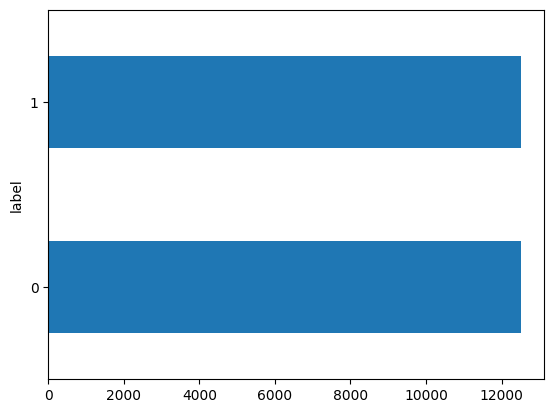

In [24]:
import matplotlib.pyplot as plt

df["label"].value_counts(ascending=True).plot.barh()
plt.show()

It is also useful to check the length of the reviews, since we will need to decide on a maximum sequence length for the models. The next cell shows summary statistics of the number of words per review. The median review has about 170 words, but some reviews are very long.

In [25]:
review_lengths = df["text"].str.split().str.len()

review_lengths.describe()

,text
count,25000.000000
mean,233.787200
std,173.733032
min,10.000000
25%,127.000000
50%,174.000000
75%,284.000000
max,2470.000000


<a id="18.5.2-applying-a-tokenizer-to-a-dataset"></a>

### 18.5.2 Applying a Tokenizer to a Dataset

Next, we will convert the text of the reviews into token ids with the DistilBERT tokenizer from Section 18.4. Since in the previous cells we set the format of the dataset to `pandas`, we first need to reset the format to the default (`type=None`), so that the dataset returns Python objects again.

Let's first apply the tokenizer to the first two reviews only, truncated to 16 tokens, to inspect the output.

Let's show next how we can use a tokenizer to convert the first 2 samples in the training dataset to sequences of tokens. Since in the previous cells we set the format of the dataset to `pandas`, we need to first re-set the format to `type=None`.

In [26]:
imdb.set_format(type=None)

# Text of the first two training reviews
texts_2 = imdb["train"][:2]
texts_2

{'text': ['I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far b

In [ ]:
imdb.set_format(type=None)

# Text of the first two training reviews
texts_2 = imdb["train"][:2]["text"]

output_tokens = tokenizer(texts_2, truncation=True, max_length=16)

for ids in output_tokens.input_ids:
    print(ids)
    print(tokenizer.convert_ids_to_tokens(ids))

[101, 1045, 12524, 1045, 2572, 8025, 1011, 3756, 2013, 2026, 2678, 3573, 2138, 1997, 2035, 102]
['[CLS]', 'i', 'rented', 'i', 'am', 'curious', '-', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', '[SEP]']
[101, 1000, 1045, 2572, 8025, 1024, 3756, 1000, 2003, 1037, 15544, 19307, 1998, 3653, 6528, 102]
['[CLS]', '"', 'i', 'am', 'curious', ':', 'yellow', '"', 'is', 'a', 'ri', '##sible', 'and', 'pre', '##ten', '[SEP]']


To tokenize the entire dataset, it is common to use the `map()` method of a `Dataset`, which applies a function to each sample in the dataset and adds the returned values as new columns. We first define a function `tokenize` that is passed to `map()`. The arguments `truncation=True` and `max_length=256` truncate reviews that are longer than 256 tokens, which keeps most of the text while reducing the computation. We do not pad the reviews at this point: padding to the longest review in each batch is done later, when the batches are formed during training, which is more efficient than padding all reviews to a fixed length.

Using the option `batched=True` in the `map()` method applies the tokenization to batches of reviews instead of one review at a time, which is much faster. As we learned in the previous section, the tokenizer returns the keys `input_ids` and `attention_mask`, which are added as new columns to the dataset.

In [ ]:
def tokenize(rows):
    return tokenizer(rows["text"], truncation=True, max_length=256)

tokenized_imdb = imdb.map(tokenize, batched=True)

In [ ]:
# Check the tokenized dataset
tokenized_imdb

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 25000
    })
})

In [ ]:
# Check the first training sample (the input_ids are truncated to at most 256 tokens)
sample = tokenized_imdb["train"][0]
print("Label:", sample["label"])
print("Number of tokens:", len(sample["input_ids"]))
print("First 20 input ids:", sample["input_ids"][:20])
print("First 20 attention mask values:", sample["attention_mask"][:20])

# The reviews have different lengths, since no padding was applied
print("Number of tokens in the first 10 reviews:", [len(ids) for ids in tokenized_imdb["train"][:10]["input_ids"]])

Label: 0
Number of tokens: 256
First 20 input ids: [101, 1045, 12524, 1045, 2572, 8025, 1011, 3756, 2013, 2026, 2678, 3573, 2138, 1997, 2035, 1996, 6704, 2008, 5129, 2009]
First 20 attention mask values: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Number of tokens in the first 10 reviews: [256, 256, 133, 185, 256, 154, 143, 256, 256, 256]


<a id="18.6-representation-of-groups-of-words"></a>

## 18.6 Representation of Groups of Words

Representation of groups of words in Machine Learning models for text processing is based on two categories of approaches:

- **Set models** approach: the text is represented as unordered collection of words. Such approaches include *bag-of-words* models.
- **Sequence models** approach: the text is represented as ordered sequences of words. These methods preserve the order of the words in the text. Representatives of these approaches are Recurrent Neural Networks, and Transformer Networks.

The order of words in natural language is not necessarily fixed, and sentences with different orders of the words can have the same meaning. Also, different languages use different ways to order the words. As a result, defining the order of the words in text in NLP tasks is not straightforward.

<a id="18.6.1-bag-of-words-models"></a>

### 18.6.1 Bag-of-Words Models
**Bag-of-words** models discard the information about the order of the words, where the term *bag* implies that the structure of the text is lost. A depiction of a bag-of-words is shown below, where the initial text is separated into word-level tokens, and a bag is created from all words in the text. Also, instead of individual words, these models often employ N-gram representations. This type of models typically consider the frequency of occurrence of each word in the training data, and a classifier is trained by using the word counts as inputs.

For instance, to create a spam filtering classifier, two bags-of-words can be created from the words in spam and non-spam emails. Presumably, the spam bag will contain trigger words (such as cheap, buy, stock) more frequently than the bag with words from non-spam emails. A classifier will be trained using the two bags-of-words and learn to differentiate trigger words from regular words. After the training, the classifier will analyze the words in new unseen messages, and predict the probability that these words belong to the spam or non-spam bag-of-words.

<img src="images/bag_of_words.png" width="600">

*Figure: Bag-of-words representation.*

The early applications of machine learning in NLP relied on bag-of-words models. Modern applications, especially those related to Large Language Models, rely predominantly on sequence models.

<a id="18.7-sequence-models-approach"></a>

## 18.7 Sequence Models Approach

**Sequence models** preserve the order of words in the input text. Typical implementation of sequence models includes representing the words in text data with integer indices, mapping the integers to vector representations, and passing the vectors to a machine learning model, where the layers in the model will account for the ordering of input vectors.

The input vectors to sequence models can be in the form of:

- One-hot word vector representation, or
- Word embeddings representation.

<a id="18.7.1-one-hot-word-vector-representation"></a>

### 18.7.1 One-Hot Word Vector Representation

**One-hot word vector** representation is similar to encoding categorical features with one-hot encoding matrix. That is, the index for each word is converted to one-hot vector, having `1 (hot)` for that word and `0 (cold)` for all other words. An example is shown in the left-hand figure, where we created a zero vector with length of 4, and assigned 1 for the index that corresponds to  every word. Another example is shown in the right-hand figure.

<img src="images/one_hot_encodding.png" width="800">

*Figure: One-hot word vector encoding.*

One-hot word vector representation is not an efficient way to represent text, because for large text datasets the input vectors can become quite large. For instance, a training set with 20,000 words will need to use one-hot vectors of size 20,000 to represent each word, and this results in slow training, as well as this type of word representation takes a lot of memory space.

Using word embeddings is more efficient, since the vectors for word representation are much smaller than the size of the vocabulary, and more importantly, embedding vectors can capture important semantic meaning of the words. Hence, most modern NLP models rely on word embeddings for representing words in text.

<a id="18.7.2-word-embeddings"></a>

### 18.7.2 Word Embeddings

**Word embeddings** representation is used to convert each word into a vector (also referred to as *embedding vector*), in such as way that the embedding vectors of words that have similar semantic meaning have close spatial positions in the embeddings space.

The embeddings space consists of the set of vectors, where each word in the vocabulary is represented with one vector. For calculating the distance between the vectors in the embeddings space, typically cosine similarity is used as a distance metric. For two vectors $u$ and $v$, *cosine similarity* is calculated as the dot (scalar, inner) product of the vectors divided by the norm of the vectors, i.e., $\dfrac{u\cdot v}{||u||\cdot ||v||}$.

Typical dimensionality of vectors for representing word embeddings in NLP models has been between 256 and 1,024. In modern LLMs, the dimensionality of token embeddings is commonly between 2,048 and 7,168. For instance, the following figure shows the embedding vector for the word 'work'. The embedding vector has many values, and each value represents some aspect of the meaning of that word.

<img src="images/embedding_vector.png" width="700">

*Figure: Embedding vector for the word 'work'.* Source: [link](https://ig.ft.com/generative-ai/)


The embedding vectors of words that have similar meanings are also similar. In the following figure, we can see that the embedding vectors of the words 'football' and 'soccer' are more similar to each other, than the embedding vectors of the words 'sea' or 'we'.

<img src="images/embeddings_comparison.png" width="500">

*Figure: Embedding vectors for words with similar meanings are also similar.* Source: [link](https://ig.ft.com/generative-ai/)


A simple example of word embeddings space is shown below, where similar words are positioned closer to each other. Therefore, the spatial distance between the vectors is dependent on the semantic meaning of the words.

<img src="images/word_embeddings.png" width="500">

*Figure: Word embeddings space.* Source: [link](https://ig.ft.com/generative-ai/)


Two popular methods for generating word embeddings are *word2vec* and *GloVe*. These methods use Neural Networks to learn embedding vectors from a large corpus of text. The resulting vectors learned by these techniques can be imported as pretrained word embeddings and applied to downstream tasks with smaller training datasets.

For example, the website  [Embedding Projector](http://projector.tensorflow.org) provides visualizations of word embeddings, and for an entered word displays other words that are adjacent in the embeddings space.

To demonstrate the use of word embeddings in PyTorch, we will first look at the embedding layer, and in the Appendix we use it in a model for sentiment analysis of the IMDB reviews that we tokenized in Section 18.5.

#### Embedding Layer in PyTorch

PyTorch provides the `nn.Embedding` layer, which we will use to project the input tokens into vectors in an embedding space. The layer requires two arguments: `num_embeddings`, the number of tokens in the vocabulary, and `embedding_dim`, the dimensionality of the vectors in the embedding space. The layer takes integer indices as inputs, and outputs embedding vectors. It can be considered as a look-up table, which maps each integer index to a row of a trainable weight matrix of size (`num_embeddings`, `embedding_dim`).

To understand how the embedding layer works, let's consider a vocabulary of 100 tokens, and our aim is to represent the tokens with 5-dimensional vectors. In the cell below, the embedding layer assigns random values to the list of indices 1, 2, and 3, and we can see that a 5-dimensional vector is assigned to each index. However, the embedding vectors are trainable, and when we include the embedding layer in a model, as we train the model, tokens that are similar will get closer in the embedding space.

In [27]:
import torch
import torch.nn as nn

# Embedding layer: represent a vocabulary of 100 tokens with 5-dimensional vectors
embedding_layer = nn.Embedding(num_embeddings=100, embedding_dim=5)

# Input: a tensor of token indices
input_ids = torch.tensor([1, 2, 3])

# Apply the embedding layer
embedding_layer(input_ids)

tensor([[ 0.4816,  0.4267, -0.8160,  0.8323,  0.1712],
        [ 0.3579, -0.8344, -1.4053, -0.2987, -0.0263],
        [-0.6856, -1.1005, -0.7759, -0.0846, -1.3001]],
       grad_fn=<EmbeddingBackward0>)

In [28]:
# The weight matrix of the layer: one row per token in the vocabulary
print(embedding_layer.weight.shape)
print(embedding_layer.weight.requires_grad)

torch.Size([100, 5])
True


<a id="18.8-models"></a>

## 18.8 Models

In this section, we will work with pretrained models directly: we will load a pretrained model by its name, fine-tune a pretrained model to our dataset, and use a model to generate text with different generation strategies. In Section 18.9, we will see how pipelines package these steps for common NLP tasks.

<a id="18.8.1-importing-a-pretrained-model"></a>

### 18.8.1 Importing a Pretrained Model

Instead of using a default model for a task, we can select any model from the many available on the Hugging Face Hub. The `AutoModel` family of classes loads the model with the right architecture for a given checkpoint name, in the same way as `AutoTokenizer` loads the right tokenizer. Different `Auto` classes correspond to different tasks: for instance, `AutoModelForCausalLM` is for causal language models that generate text (such as GPT-2, Llama, Qwen, or SmolLM2), `AutoModelForSequenceClassification` is for text classification, and `AutoModelForQuestionAnswering` is for question answering.

Let's load `SmolLM2-360M`, a small modern language model released by Hugging Face in 2024, together with its tokenizer. It has 360 million parameters, so it is fast enough to run on a CPU, and we will use it in Section 18.8.3 to generate text. The argument `pad_token_id` is optional, and its purpose is to define the id of the token used for padding the text sequences. In this case, the id of the padding token is set to the id of the end-of-sequence token (`eos_token_id`), which is a common choice for language models that do not have a dedicated padding token. We also set the device for the models (GPU if available, as in Lecture 15), and move the model to it.

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForCausalLM

# Device for the models: GPU if available, otherwise CPU
torch_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_name = "HuggingFaceTB/SmolLM2-360M"

gen_tokenizer = AutoTokenizer.from_pretrained(model_name)
gen_model = AutoModelForCausalLM.from_pretrained(model_name, pad_token_id=gen_tokenizer.eos_token_id)
gen_model.to(torch_device);

As we mentioned in Section 18.3, the loaded model is a regular PyTorch `nn.Module`. We can check this in the next cell, count its parameters (about 362 million), and print its architecture, which consists of an embedding layer, a stack of 32 Transformer decoder blocks (explained in Lecture 19), and an output layer that predicts the next token.

In [ ]:
print("Is nn.Module:", isinstance(gen_model, nn.Module))
print("Number of parameters:", sum(p.numel() for p in gen_model.parameters()))

gen_model

Is nn.Module: True
Number of parameters: 361821120


LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 960, padding_idx=0)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=960, out_features=960, bias=False)
          (k_proj): Linear(in_features=960, out_features=320, bias=False)
          (v_proj): Linear(in_features=960, out_features=320, bias=False)
          (o_proj): Linear(in_features=960, out_features=960, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=960, out_features=2560, bias=False)
          (up_proj): Linear(in_features=960, out_features=2560, bias=False)
          (down_proj): Linear(in_features=2560, out_features=960, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((960,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((960,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((960,), eps=1e-05)
    (r

<a id="18.8.2-fine-tuning-a-pretrained-model"></a>

### 18.8.2 Fine-tuning a Pretrained Model

This section demonstrates how to **fine-tune** a pretrained model on our own dataset. Fine-tuning starts from the parameters of a model pretrained on a large text corpus, and continues the training on a (typically much smaller) task-specific dataset. We will fine-tune the DistilBERT model for classification of the IMDB reviews, and compare it with the simple embedding model in the Appendix.

We will use the tokenized dataset `tokenized_imdb` from Section 18.5, which was created with the tokenizer of the same `distilbert-base-uncased` checkpoint. This is important: a model must always be used with the tokenizer it was pretrained with.

Fine-tuning a Transformer model is considerably more expensive than training a small model such as the one in the Appendix. To keep the training time short (a few minutes on a GPU in Google Colab), we will fine-tune on a random subset of 5,000 training reviews, and evaluate on a subset of 5,000 test reviews. Since the training set is sorted by label, we shuffle it before selecting the subset. Fine-tuning on the full dataset improves the accuracy by a couple of percentage points, at the cost of about 20 minutes of training.

In [ ]:
train_subset = tokenized_imdb["train"].shuffle(seed=42).select(range(5000))
test_subset = tokenized_imdb["test"].shuffle(seed=42).select(range(5000))

train_subset

Next, we will load the DistilBERT model for classification with the `AutoModelForSequenceClassification` class. The argument `num_labels=2` adds a classification *head* with 2 outputs on top of the pretrained Transformer encoder, and the arguments `id2label` and `label2id` assign names to the two output labels, which will be used when the model reports its predictions. The parameters of the encoder are loaded from the pretrained checkpoint, whereas the parameters of the classification head are newly (randomly) initialized, which is what the message in the cell output tells us (the parameters of the classification head are listed as missing from the checkpoint and newly initialized), and why the model needs to be trained on our task before it can be used.

In [ ]:
from transformers import AutoModelForSequenceClassification

clf_model = AutoModelForSequenceClassification.from_pretrained(model_ckpt, num_labels=2,
                                                               id2label={0: "negative", 1: "positive"},
                                                               label2id={"negative": 0, "positive": 1})

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Being an `nn.Module`, the model can be inspected like any PyTorch model. The next cell prints the classification head: a pre-classifier layer, a ReLU activation, a dropout layer, and the final linear layer with 2 outputs, which are applied to the output of the Transformer encoder.

In [ ]:
print(clf_model.pre_classifier)
print(clf_model.dropout)
print(clf_model.classifier)

Linear(in_features=768, out_features=768, bias=True)
Dropout(p=0.2, inplace=False)
Linear(in_features=768, out_features=2, bias=True)


The model also contains the embedding layer that we discussed in Section 18.7.2, which maps each of the 30,522 tokens in the vocabulary to a 768-dimensional vector. Differently from the randomly initialized layer in the `nn.Embedding` example, these embedding vectors were learned during the pretraining of DistilBERT on a large text corpus, and they already capture the semantic similarity between words. In the next cell, we extract the embedding vectors of several words, and calculate the cosine similarity between them. We can see that *football*, *soccer*, and *basketball* are more similar to each other than to *sea* and *ocean*, which in turn are similar to each other, whereas *computer* is dissimilar to all of them.

Note that these are the *input* embeddings of the model, which are the same for a word regardless of the context. The Transformer blocks of the model further transform these vectors based on the surrounding words, which produces *contextual* representations (explained in Lecture 19).

In [ ]:
import pandas as pd

# The embedding layer of DistilBERT: one 768-dimensional vector per token in the vocabulary
embedding_layer = clf_model.distilbert.embeddings.word_embeddings
print(embedding_layer)

# Embedding vectors of several words
words = ["football", "soccer", "basketball", "sea", "ocean", "computer"]
ids = tokenizer.convert_tokens_to_ids(words)
vectors = embedding_layer.weight[ids]

# Cosine similarity between every pair of vectors
similarity = torch.nn.functional.cosine_similarity(vectors.unsqueeze(1), vectors.unsqueeze(0), dim=-1)

pd.DataFrame(similarity.detach().numpy().round(2), index=words, columns=words)

Embedding(30522, 768, padding_idx=0)


,football,soccer,basketball,sea,ocean,computer
football,1.00,0.57,0.61,0.16,0.23,0.33
soccer,0.57,1.00,0.58,0.24,0.34,0.33
basketball,0.61,0.58,1.00,0.27,0.32,0.35
sea,0.16,0.24,0.27,1.00,0.58,0.30
ocean,0.23,0.34,0.32,0.58,1.00,0.37
computer,0.33,0.33,0.35,0.30,0.37,1.00


We could train this model with the standard PyTorch training loop from Lecture 15 (see also the Appendix), by passing `input_ids`, `attention_mask`, and `labels` to the model (Hugging Face models calculate the loss internally when `labels` are provided). Instead, we will use the `Trainer` class in the Transformers library, which implements the training loop for us, similarly to `model.fit` in TensorFlow-Keras, and adds useful features such as logging, evaluation during training, checkpointing, and mixed-precision training on GPUs.

The training parameters are first defined with the class `TrainingArguments`, as shown in the next cell. In this case, the arguments include the output directory to save the training outputs, the evaluation strategy, the learning rate, the batch sizes for training and evaluation, the number of training epochs, the weight decay, and whether to report the results to external tools.

In [ ]:
from transformers import TrainingArguments

# Define training arguments for the model
training_args = TrainingArguments(
    # Directory to save model checkpoints and logs
    output_dir="distilbert-imdb",
    # Evaluation strategy - evaluate the model at the end of each epoch
    eval_strategy="epoch",
    # Learning rate for the optimizer (AdamW by default)
    learning_rate=2e-5,
    # Batch size for training
    per_device_train_batch_size=16,
    # Batch size for evaluation
    per_device_eval_batch_size=32,
    # Number of training epochs
    num_train_epochs=2,
    # Weight decay to apply for regularization
    weight_decay=0.01,
    # Disable reporting to external tools (e.g., WandB, TensorBoard)
    report_to="none"
)

We will also define a function called `compute_metrics` to calculate the accuracy at the end of each epoch.

In [ ]:
from sklearn.metrics import accuracy_score

# Function to compute metrics during training
def compute_metrics(eval_pred):
    outputs, labels = eval_pred
    predictions = outputs.argmax(axis=-1)
    acc = accuracy_score(labels, predictions)
    return {"accuracy": acc}

Next, we will define our `trainer` as an instance of the `Trainer` class by passing the model, the training arguments, the training and evaluation datasets, the tokenizer, and the function for computing the performance metrics. The `Trainer` uses the columns `input_ids`, `attention_mask`, and `label` of the datasets, and ignores the other columns (such as `text`). Afterward, we start the training by running `trainer.train()`. The loss and accuracy values are reported after each epoch.

Since the tokenized reviews have different lengths, we also pass a `DataCollatorWithPadding` object to the `Trainer` as the `data_collator` argument. The collator pads the sequences in each batch to the longest sequence in that batch (*dynamic padding*), using the padding token of the tokenizer, so that the batch can be converted into a tensor. This is more efficient than padding all reviews to a fixed length, because short reviews are padded only as much as necessary.

In [ ]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [ ]:
from transformers import Trainer

# Initialize the Trainer with the required parameters
trainer = Trainer(
    model=clf_model,
    args=training_args,
    train_dataset=train_subset,
    eval_dataset=test_subset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Next, let's evaluate the model performance on the test subset. Even with only 5,000 training reviews and 2 epochs, the fine-tuned DistilBERT model achieves an accuracy of about 90%, which is higher than the accuracy of the simple embedding model in the Appendix trained on all 25,000 reviews. This illustrates the main advantage of fine-tuning: the pretrained model already encodes a great deal of knowledge about language, which is transferred to our task.

In [ ]:
# Evaluate the model on the test subset
test_metrics = trainer.evaluate(eval_dataset=test_subset)

# Print the evaluation metrics
print(test_metrics)

In addition, let's predict the labels for the four reviews shown below. First, we apply the tokenizer to prepare the inputs, and move them to the device of the model (the `Trainer` moved the model to the GPU, if available).

In [ ]:
# List of reviews to classify
test_texts = ["This movie was a complete waste of time. The plot made no sense and the acting was terrible.",
              "A beautifully shot film with outstanding performances. I enjoyed every minute of it!",
              "The plot was predictable, but the soundtrack and the visuals were great.",
              "I expected much more from this director. Disappointing."]

# Tokenize the reviews, pad them to the same length for batch processing
inputs = tokenizer(test_texts, return_tensors="pt", padding=True, truncation=True).to(clf_model.device)
inputs

In the next cell, we pass the inputs to the model, and use `argmax` over the output logits to obtain the predicted labels. The model is set to evaluation mode, and the forward pass is performed without gradient tracking, as in Lecture 15.

In [ ]:
clf_model.eval()
with torch.no_grad():
    outputs = clf_model(**inputs)

# Predicted labels for each review
predicted_labels = outputs.logits.argmax(dim=-1).cpu().tolist()
print("Predicted labels:", predicted_labels)

To interpret the predicted labels, we retrieve the class names from the dataset features, and print the reviews with the names of the predicted classes.

In [ ]:
class_names = imdb["train"].features["label"].names

for text, label in zip(test_texts, predicted_labels):
    print(f"{class_names[label]}: {text}")

<a id="18.8.3-generation-strategies"></a>

### 18.8.3 Generation Strategies

To generate text with a pretrained language model using the Hugging Face library, we will use the `generate()` method of the model. The generation process involves making several choices, each with its own set of advantages and trade-offs. Based on the selected generation strategy, the model output can vary significantly.

Let's consider the sentence `input_string` in the next cell. We will first preprocess it with the tokenizer to encode it into a sequence of integers. The argument `return_tensors="pt"` specifies that the output should be returned as PyTorch tensors, where `"pt"` stands for PyTorch. This argument is required when we plan to pass the tokenized sequence to a PyTorch model. We also move the tensors to the same device as the model.

In [ ]:
input_string = "Yesterday I spent several hours in the library, studying"
input_tokens = gen_tokenizer(input_string, return_tensors="pt").to(torch_device)

In [ ]:
# Check the tokenized sequence
input_tokens

{'input_ids': tensor([[   73, 15955,   339,  4957,  1545,  2737,   281,   260,  4971,    28,
          4836]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

Next, we will use the model for text generation with the `generate()` method, to generate text that continues the input sentence. The argument `max_new_tokens` tells the model to generate at most 50 new tokens, and `**input_tokens` is used to unpack the dictionary `input_tokens` (recall from Lecture 3 on calling a function with two asterisks `**`). In this case, `input_tokens` is a dictionary with keys `'input_ids'` and `'attention_mask'`.

Afterward, we use the tokenizer with the `decode()` method to convert the generated sequence of token ids back into a text string.

By default, `generate()` uses *greedy search*: at each step, it selects the token with the highest probability. Notice the repetitions in the generated text below (e.g., of the phrase "the history of the United States"). Greedy search tends to produce such repetitive text, since the model keeps choosing the same high-probability continuation, and it can get stuck in a loop. To deal with this, we can apply different generation strategies, as explained next.

In [ ]:
output_greedy = gen_model.generate(**input_tokens, max_new_tokens=50)

print(gen_tokenizer.decode(output_greedy[0], skip_special_tokens=True))

Yesterday I spent several hours in the library, studying the history of the United States. I was surprised to find that the history of the United States is not a history of the United States, but a history of the United States as a nation.

The United States is a nation, not a


#### Search Methods

Two common methods for generating text with Language Models are:

 - **Greedy search**, selects the word with the highest probability as the next word. The major drawback of greedy search is that it can miss potentially high-probability words that follow a low-probability word. Therefore, although each individual word may be the best fit when generating a response, the entire generated text can be less relevant for the query.
 - **Beam search**, selects a sequence of words (beam) that has the overall highest probability. This approach reduces the risk of missing high-probability words, because rather than focusing only on the next word in a sequence, beam search looks at the probability of the entire response.

Beam search is typically preferred over greedy search, because with beam search, the model can consider multiple routes and find the best option.

For example, in the following figure, the input query to the model is "The Financial Times is ...". The model created four possible beams with a potential response, and out of the four beams, the third beam "a newspaper founded in 1888" was selected as the most coherent human-like response.

<img src='images/beam_search.png' width=500px>

*Figure: Beam search example.* Source: [link](https://ig.ft.com/generative-ai/)

Let's apply a beam search strategy to the same input. This is shown in the following cell, where beam search examines multiple probable solutions (beams) for the generated text, that is set by the argument `num_beams=8`. We also applied a penalty term for repeating the same two consecutive words with the argument `no_repeat_ngram_size=2`. By considering several possible solutions, the beam search algorithm tries to improve the generated output text by the model.

In [ ]:
output_beam = gen_model.generate(**input_tokens, max_new_tokens=50, num_beams=8, no_repeat_ngram_size=2)

print(gen_tokenizer.decode(output_beam[0], skip_special_tokens=True))

Yesterday I spent several hours in the library, studying for a test, and I have to say, it was one of the best things I’ve ever done.

The library is a great place to study, because it’s quiet and there are no distractions. Plus, the books are


#### Sampling-based Methods

Greedy search and beam search aim to find the best sequence of tokens that maximizes the likelihood of the generated text. Beside search methods,  modern language models also employ **sampling-based methods** that introduce controlled randomness to generate more diverse and creative text. Instead of always choosing the most likely tokens, these methods sample from the model's probability distribution, allowing for variability in the generated output.

Sampling-based methods are especially useful for tasks like creative writing, dialogue generation, and open-ended text completion.

Sampling-based strategies include the following.

1. Temperature Sampling

**Temperature** controls the randomness of predictions by scaling the logits (raw prediction scores) before the softmax activation function in the output layer. A typical default temperature value is 1.0. Lower temperature values in the range 0.1 - 0.7 make the model more confident and deterministic, whereas higher temperature values in the range 1.0 - 2.0 increase randomness and creativity in the generated text.

The next example shows two different responses with a low and high temperature. The argument `do_sample=True` specifies that the model should sample from the probability distribution of possible next tokens.

Since sampling is random, the generated text is different every time the cell is run. For reproducibility of the examples, we set a random seed before each generation with the `set_seed()` function from the Transformers library.

In [ ]:
from transformers import set_seed

input_string = "The secret door opened, revealing"
input_tokens = gen_tokenizer(input_string, return_tensors="pt").to(torch_device)

To understand how the sampling methods work, let's first look at what the model actually outputs. For a given input sequence, the model outputs a vector of *logits* for the next token, with one value for each of the 49,152 tokens in the vocabulary, and the softmax function converts the logits into a probability distribution over the next token. Greedy search simply picks the token with the highest probability, whereas the sampling-based methods draw the next token at random from this distribution, after modifying it in different ways. The next cell shows the 10 most probable next tokens after the prompt `"The secret door opened, revealing"`.

In [ ]:
# Logits for the next token after the prompt, from a single forward pass through the model
with torch.no_grad():
    logits = gen_model(**input_tokens).logits[0, -1]

# Convert the logits into probabilities, and display the 10 most probable next tokens
probs = torch.softmax(logits, dim=-1)
top = torch.topk(probs, 10)
for p, idx in zip(top.values, top.indices):
    print(f"{gen_tokenizer.decode(idx)!r:>12}  {p.item():.3f}")

        ' a'  0.578
      ' the'  0.089
       ' an'  0.069
      ' two'  0.027
  ' another'  0.015
       ' Mr'  0.008
    ' three'  0.007
     ' that'  0.005
      ' her'  0.004
       ' Dr'  0.003


Temperature sampling divides the logits by the temperature before the softmax. The next cell shows how this changes the probabilities of the five most probable tokens: a low temperature makes the distribution more peaked (the most probable token is selected almost always), and a high temperature makes it flatter (many tokens have a similar chance of being selected). Top-K sampling keeps only the K most probable tokens of this distribution, and top-P sampling keeps the most probable tokens whose probabilities add up to P, before sampling the next token.

In [ ]:
import pandas as pd

temperatures = [0.3, 1.0, 1.5]
top5 = torch.topk(probs, 5).indices

table = {f"T = {t}": torch.softmax(logits.float() / t, dim=-1)[top5].numpy().round(3) for t in temperatures}
pd.DataFrame(table, index=[gen_tokenizer.decode(i) for i in top5])

,T = 0.3,T = 1.0,T = 1.5
a,0.997,0.579,0.113
the,0.002,0.089,0.032
an,0.001,0.069,0.027
two,0.000,0.027,0.015
another,0.000,0.015,0.010


In [ ]:
# Low temperature - more focused and deterministic
set_seed(0)
output_low_temp = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, temperature=0.3)

# High temperature - more random and creative
set_seed(0)
output_high_temp = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, temperature=1.5)

print("Low Temperature Output:")
print(gen_tokenizer.decode(output_low_temp[0], skip_special_tokens=True))
print("\nHigh Temperature Output:")
print(gen_tokenizer.decode(output_high_temp[0], skip_special_tokens=True))

Low Temperature Output:
The secret door opened, revealing a small room filled with a strange object. It was a small box, with a label that read "Einstein's Brain."

"What is this?" asked Alice.

"It's Einstein's brain," replied the voice. "It's been preserved in a jar of formaldehyde for

High Temperature Output:
The secret door opened, revealing a dusty old closet, cluttered with old furniture and hidden objects strewn all over it, and all at odd prices. Behind was another set of strange tools and a door that led a dingey black-haired woman towards a set of shelves and then doors with hidden locks behind them.


2. Top-K Sampling

**Top-K sampling** limits the model to selecting from only the K most likely next tokens at each step. At each generation step, the model keeps only the top K tokens (those with the highest probability), and samples randomly from this reduced set of tokens. Instead of selecting the token with the highest probability as in greedy search, top-K sampling considers several most likely tokens at each step.

A typical default value for K is 50. Small K values in the range 10-20 result in more focused but less diverse response, and large K values over 100 produce more diverse but potentially less coherent text.

In [ ]:
# Top-K sampling with K=10
set_seed(0)
output_low_topk = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, top_k=10)

# Top-K sampling with K=100
set_seed(0)
output_high_topk = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, top_k=100)

print("Low Top-K Output:")
print(gen_tokenizer.decode(output_low_topk[0], skip_special_tokens=True))
print("\nHigh Top-K Output:")
print(gen_tokenizer.decode(output_high_topk[0], skip_special_tokens=True))

Low Top-K Output:
The secret door opened, revealing a room lined with paintings and sculptures. There sat Mr. and Mrs. Smith, both very busy, but excited about the new addition to their lives.

Mr. Smith, a wise old man, sat next to his wife, holding a picture of a beautiful garden with colorful flowers. "

High Top-K Output:
The secret door opened, revealing a room lined with papers cluttered with the documents of an army's recruitment drive. Behind them was another room where someone was speaking softly to another. The other person was speaking calmly, looking up at someone sitting behind a desk.

"Hi, sir," the person on the phone said.


3. Top-P (Nucleus) Sampling

**Top-P sampling** (also called nucleus sampling) selects the smallest set of tokens whose cumulative probability exceeds a chosen threshold P. It ranks all tokens by probability and samples from a reduced "nucleus" of tokens with cumulative probability greater than P.

When the model is confident fewer tokens are considered, and when the model is uncertain more tokens are included. A typical default value for P is 0.9. Lower values for P in the range 0.5-0.7 produce more deterministic and focused outputs, while higher values for P in the range 0.95-1.0 result in more diverse and creative outputs.

In [ ]:
# Top-P sampling with P=0.5
set_seed(0)
output_low_topp = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, top_p=0.5)

# Top-P sampling with P=0.95
set_seed(0)
output_high_topp = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, top_p=0.95)

print("Low Top-P Output:")
print(gen_tokenizer.decode(output_low_topp[0], skip_special_tokens=True))
print("\nHigh Top-P Output:")
print(gen_tokenizer.decode(output_high_topp[0], skip_special_tokens=True))

Low Top-P Output:
The secret door opened, revealing a room filled with colorful tiles. Each tile represented a different shape, color, or pattern. A friendly robot named TileBot greeted them and showed them how to arrange the tiles in a special way called "tiling."

TileBot explained, "When we put all the tiles together

High Top-P Output:
The secret door opened, revealing a room lined with paintings and sculptures. There sat Mr. and Mrs. Smith, both very busy, but Mrs. Smith seemed nervous.

"Mr. Smith," she began hesitantly, "I've got something important for you."

Mr. Smith looked at her with surprise before


It is also possible to combine different sampling methods as in the next example.

In [ ]:
# Combination: top_k=60, top_p=0.95, temperature=1.5
set_seed(0)
output = gen_model.generate(**input_tokens, max_new_tokens=60, do_sample=True, top_k=60, top_p=0.95, temperature=1.5)

print(gen_tokenizer.decode(output[0], skip_special_tokens=True))

The secret door opened, revealing a dusty old closet, cluttered with old furniture and hidden objects strewn all over it, and all at odd prices. Behind was another set of strange tools and a door that led a dingy room behind it. "What's the secret to the hidden doors?" Alex asked with a bored


Other parameters in `model.generate` include:

- `repetition_penalty`: Discourages the model from repeating the same tokens or phrases. Values > 1.0 penalize repetition, and values over 1.2-1.5 reduce repetition more aggressively.
- `length_penalty`: Controls the model's preference for longer or shorter sequences (mainly used with beam search). Values < 1.0 favor shorter responses, and values > 1.0 favor longer responses.
- `no_repeat_ngram_size`: Prevents repeating any n-gram of the specified size. We used it above in beam search example.
- `min_new_tokens` and `max_new_tokens`: Define the minimum and maximum number of generated tokens (the older `max_length` argument counts the prompt tokens as well).

Recommendations for text generation:

- Use lower temperature for factual tasks, and higher temperature for creative tasks.
- Enable `do_sample=True` when using temperature, top-K, or top-P sampling.
- Start with default values, such as `top_p=0.9`, `temperature=1.0`, and `top_k=50`.
- Use `repetition_penalty` to avoid loops and repetitive phrases, especially with smaller models.
- Combine sampling methods `top_k`, `top_p`, and `temperature` for better control of diversity and coherence.
- Generate multiple sequences with `num_return_sequences` and select the best one.

Finally, note that *instruction-tuned* versions of language models (e.g., `SmolLM2-360M-Instruct`) are trained to follow instructions and answer questions in a conversation, rather than simply continuing the input text. These models, and how to prompt them, are covered in Lecture 20.

<a id="18.9-nlp-pipelines"></a>

## 18.9 NLP Pipelines

The simplest way to use a pretrained model from Hugging Face is through the **Pipelines** API, which allows us to perform a variety of NLP tasks with a few lines of code through the `pipeline()` function. A pipeline bundles together a tokenizer that preprocesses the input text, a pretrained model, and the postprocessing of the model outputs into a readable result.

The `pipeline()` method has the following syntax:

```
from transformers import pipeline

# Pipeline to use a default model & tokenizer for a given task
pipeline("<task-name>")

# Pipeline to use an existing or custom model
pipeline("<task-name>", model="<model_name>")

# Pipeline to use an existing or custom model and tokenizer
pipeline('<task-name>', model='<model name>', tokenizer='<tokenizer_name>')
```

Among the currently available task pipelines are:

- Sentiment analysis
- Question answering
- Translation
- Summarization
- Text generation
- NER (named entity recognition)
- Zero shot classification
- Fill mask

In the following subsections, we will examine examples of using the `pipeline("<task-name>")` function with different NLP tasks. As we mentioned, if we don't provide the names of the model and tokenizer, the pipeline will assign a default model and tokenizer for the task, and it will download the model parameters and other required files from the Hugging Face Hub (the first time a model is used; afterward it is loaded from the local cache).

The Transformers library by Hugging Face is preinstalled in Google Colab. If you don't run this notebook in Google Colab, you will need to first install the library with `pip install transformers`.

Pipelines and models run on a GPU when one is available. In the next cell, we set the `device` argument that will be passed to the pipelines: `0` selects the first GPU, and `-1` selects the CPU. In Google Colab, select a GPU runtime via *Runtime* > *Change runtime type* (see Tutorial 5).

In [ ]:
import torch
from transformers import pipeline

# 0 = first GPU, -1 = CPU
device = 0 if torch.cuda.is_available() else -1
print("Using device:", "GPU" if device == 0 else "CPU")

Using device: CPU


<a id="18.9.1-sentiment-analysis"></a>

### 18.9.1 Sentiment Analysis

The first example uses `pipeline()` for sentiment analysis. Sentiment analysis is a text classification task, where the goal is to classify a text (e.g., a movie review) as positive or negative. In the Appendix, we train our own model for this task.

When the cell is executed, the pipeline will select a default pretrained model for sentiment analysis in English, it will download the model and the related tokenizer, and it will instantiate a text classifier object. In this case, we can see in the cell output that the used default pretrained model is `distilbert-base-uncased-finetuned-sst-2-english`.

In [ ]:
classifier = pipeline("sentiment-analysis", device=device)

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0


In the next cell, the classifier is applied to a sentence. The output is the predicted label and the confidence score.

In [ ]:
classifier("I fully understand what you are saying.")

[{'label': 'POSITIVE', 'score': 0.9996806383132935}]

The pipeline allows to pass multiple sentences, and it will return a sentiment label and confidence score for each sentence.

In [ ]:
classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
)

[{'label': 'POSITIVE', 'score': 0.9598046541213989},
 {'label': 'NEGATIVE', 'score': 0.9994558691978455}]

A pipeline can also be created from a model and a tokenizer that we loaded or fine-tuned ourselves, by passing them as the `model` and `tokenizer` arguments. The next cell creates a sentiment analysis pipeline from the DistilBERT model that we fine-tuned on the IMDB reviews in Section 18.8.2. The pipeline applies the tokenizer, runs the model, and converts the output logits into the label names that we assigned with `id2label` and a confidence score, which is exactly what we did manually in Section 18.8.2.

In [ ]:
# Sentiment analysis pipeline with our fine-tuned model
our_classifier = pipeline("sentiment-analysis", model=clf_model, tokenizer=tokenizer, device=device)

our_classifier(["This movie was a complete waste of time. The plot made no sense and the acting was terrible.",
                "A beautifully shot film with outstanding performances. I enjoyed every minute of it!"])

<a id="18.9.2-question-answering"></a>

### 18.9.2 Question Answering

This pipeline answers questions using information from a given context. Such pipeline can be very useful when we are dealing with long text data and finding answers to questions in the document can take time.

In [ ]:
question_answerer = pipeline("question-answering", device=device)

No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5 (https://huggingface.co/distilbert/distilbert-base-cased-distilled-squad).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0


We provide the inputs to the pipeline as the `question` and `context` keyword arguments. The model extracts information from the provided context and returns a dictionary with a confidence score, the start and end characters of the answer in the context, and the answer. Also note that the model does not generate new text to answer the questions, but instead it searches for the answer in the supplied context sequence.

In [ ]:
question_answerer(
    question="What didn't cross the street?",
    context="The animal didn't cross the street because it was too tired",
)

{'score': 0.755366325378418, 'start': 0, 'end': 10, 'answer': 'The animal'}

In [ ]:
question_answerer(
    question="Why the animal didn't cross the street?",
    context="The animal didn't cross the street because it was too wide",
)

{'score': 0.6076138019561768,
 'start': 43,
 'end': 58,
 'answer': 'it was too wide'}

<a id="18.9.3-machine-translation"></a>

### 18.9.3 Machine Translation
For machine translation, we can provide source and target languages in the pipeline, as in the next cell where the task `"translation_en_to_fr"` is to translate text from English to French. Although this pipeline can work with several languages, most often, machine translation requires to specify the name of the used language model, and only for several special cases it can work by specifying only the task name.

In [ ]:
translator = pipeline("translation_en_to_fr", device=device)

No model was supplied, defaulted to google-t5/t5-base and revision a9723ea (https://huggingface.co/google-t5/t5-base).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0


In [ ]:
translator("I am a student")

[{'translation_text': 'Je suis un étudiant'}]

In [ ]:
translator("Peyton Manning became the first quarterback ever to lead two different teams to multiple Super Bowls.")

[{'translation_text': 'Peyton Manning est devenu le premier quarterback à conduire deux équipes différentes à plusieurs Super Bowls.'}]

<a id="18.9.4-text-summarization"></a>

### 18.9.4 Text Summarization
Text summarization reduces a longer text into a shorter summary.

In [ ]:
summarizer = pipeline("summarization", device=device)

No model was supplied, defaulted to sshleifer/distilbart-cnn-12-6 and revision a4f8f3e (https://huggingface.co/sshleifer/distilbart-cnn-12-6).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0


In [ ]:
summarizer(
    """
    America has changed dramatically during recent years. Not only has the number of
    graduates in traditional engineering disciplines such as mechanical, civil,
    electrical, chemical, and aeronautical engineering declined, but in most of
    the premier American universities engineering curricula now concentrate on
    and encourage largely the study of engineering science. As a result, there
    are declining offerings in engineering subjects dealing with infrastructure,
    the environment, and related issues, and greater concentration on high
    technology subjects, largely supporting increasingly complex scientific
    developments. While the latter is important, it should not be at the expense
    of more traditional engineering.

    Rapidly developing economies such as China and India, as well as other
    industrial countries in Europe and Asia, continue to encourage and advance
    the teaching of engineering. Both China and India, respectively, graduate
    six and eight times as many traditional engineers as does the United States.
    Other industrial countries at minimum maintain their output, while America
    suffers an increasingly serious decline in the number of engineering graduates
    and a lack of well-educated engineers.
"""
)

[{'summary_text': ' The number of engineering graduates in the United States has declined in recent years . China and India graduate six and eight times as many traditional engineers as the U.S. does . Rapidly developing economies such as China continue to encourage and advance the teaching of engineering . There are declining offerings in engineering subjects dealing with infrastructure, infrastructure, the environment, and related issues .'}]

Specifying the `min_length` and `max_length` arguments allows to control the length of the summary.

In [ ]:
summarizer(
    """
    Flooding on the Yangtze river remains serious although water levels on parts of the river decreased
    today, according to the state headquarters of flood control and drought relief .
    """, min_length=8, max_length=20)

[{'summary_text': ' Flooding on the Yangtze river remains serious although water levels on parts of the'}]

In [ ]:
summarizer(
    """BAGHDAD -- Archaeologists in northern Iraq last week unearthed 2,700-year-old rock carvings featuring war scenes and trees from the Assyrian Empire, an archaeologist said Wednesday.
    The carvings on marble slabs were discovered by a team of experts in Mosul, Iraq’s second-largest city, who have been working to restore the site of the ancient Mashki Gate, which was bulldozed by Islamic State group militants in 2016.
    Fadhil Mohammed, head of the restoration works, said the team was surprised by discovering “eight murals with inscriptions, decorative drawings and writings.”
    Mashki Gate was one of the largest gates of Nineveh, an ancient Assyrian city of this part of the historic region of Mesopotamia.
    The discovered carvings show, among other things, a fighter preparing to fire an arrow while others show palm trees.
    """)

[{'summary_text': ' The carvings on marble slabs were discovered by a team of experts in Mosul, Iraq’s second-largest city . They have been working to restore the site of the ancient Mashki Gate, which was bulldozed by Islamic State group militants in 2016 . Mashki gate was one of the largest gates of Nineveh, an ancient Assyrian city of this part of Mesopotamia .'}]

<a id="18.9.5-text-generation"></a>

### 18.9.5 Text Generation

In this example, we will use the `"text-generation"` pipeline to generate text that continues a provided prompt.

The default model for this pipeline is GPT-2 from 2019, which produces rather poor text by today's standards. Instead, we will specify the model to use with the `model` argument. We will use `SmolLM2-360M`, a small modern language model released by Hugging Face in 2024. It has 360 million parameters, so it is fast enough to run on a CPU, and it generates noticeably more coherent text. Larger models (e.g., with 1 to 8 billion parameters) are used in exactly the same way, by changing the model name, but they require a GPU with sufficient memory. This is the same model that we used in Section 18.8 to explore different text generation strategies.

In [ ]:
generator = pipeline("text-generation", model="HuggingFaceTB/SmolLM2-360M", device=device)

Now let's provide a prompt text to the generator object, and the generator will continue the text. The argument `max_new_tokens` sets the maximum number of tokens to generate after the prompt. Note that text generation involves randomness, so some of the outputs will not be perfect. And admittedly, this is one of the most difficult NLP tasks.

In [ ]:
outputs_1 = generator("In this course, we will teach you how to", max_new_tokens=60)

print(outputs_1[0]['generated_text'])

In this course, we will teach you how to create amazing stories set in the world of comics and graphic novels. You'll learn the basics of visual storytelling and how to craft compelling narratives that will captivate your readers. We'll also cover essential techniques for creating memorable characters, immersive worlds, and dynamic conflicts. So grab a pencil and some paper (or


In [ ]:
outputs_2 = generator("Niagara Falls is a city located in", max_new_tokens=60)

print(outputs_2[0]['generated_text'])

Niagara Falls is a city located in the State of New York, U.S. The name of the city came from the town of the same name in Scotland, and is derived from the Scottish Gaelic word for "the falls".[7] The name of the city is in fact "Niagara Falls", a name that was applied


<a id="18.9.6-named-entity-recognition"></a>

### 18.9.6 Named Entity Recognition
Named Entity Recognition (NER), also known as named entity tagging, is a task of identifying parts of the input that represent entities. Examples of entities are:

- Location (LOC)
- Organizations (ORG)
- Persons (PER)
- Miscellaneous entities (MISC)

In [ ]:
ner = pipeline("ner", grouped_entities=True, device=device)

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496 (https://huggingface.co/dbmdz/bert-large-cased-finetuned-conll03-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
Some weights of the model checkpoint at dbmdz/bert-large-cased-finetuned-conll03-english were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cuda:0
/usr/lo

In [ ]:
text_1 = "Abraham Lincoln was a president who lived in the United States."

print(ner(text_1))

[{'entity_group': 'PER', 'score': np.float32(0.9988935), 'word': 'Abraham Lincoln', 'start': 0, 'end': 15}, {'entity_group': 'LOC', 'score': np.float32(0.99965084), 'word': 'United States', 'start': 49, 'end': 62}]


Or, we can use Pandas to display the output.

In [ ]:
import pandas as pd

pd.DataFrame(ner(text_1))

,entity_group,score,word,start,end
0,PER,0.998893,Abraham Lincoln,0,15
1,LOC,0.999651,United States,49,62


In [ ]:
text_2 = """BAGHDAD -- Archaeologists in northern Iraq last week unearthed 2,700-year-old rock carvings featuring war scenes and trees from the Assyrian Empire, an archaeologist said Wednesday.
    The carvings on marble slabs were discovered by a team of experts in Mosul, Iraq’s second-largest city, who have been working to restore the site of the ancient Mashki Gate, which was bulldozed by Islamic State group militants in 2016.
    Fadhil Mohammed, head of the restoration works, said the team was surprised by discovering “eight murals with inscriptions, decorative drawings and writings.”
    Mashki Gate was one of the largest gates of Nineveh, an ancient Assyrian city of this part of the historic region of Mesopotamia.
    The discovered carvings show, among other things, a fighter preparing to fire an arrow while others show palm trees.
    """

pd.DataFrame(ner(text_2))

,entity_group,score,word,start,end
0,LOC,0.434807,BA,0,2
1,LOC,0.999473,Iraq,38,42
2,MISC,0.893630,Assyrian,132,140
3,LOC,0.782092,Empire,141,147
4,LOC,0.999238,Mosul,255,260
5,LOC,0.999156,Iraq,262,266
6,LOC,0.971527,Mashki Gate,347,358
7,ORG,0.997262,Islamic State,383,396
8,PER,0.999300,Fadhil Mohammed,426,441
9,LOC,0.974939,Mashki Gate,589,600


<a id="18.9.7-zero-shot-classification"></a>

### 18.9.7 Zero-shot Classification
Zero-shot classification is a task to classify text documents, where the term
*zero-shot* classification refers to tasks for which a language model has not been trained. I.e., the model was not trained to classify documents using the provided type of labels in the next example.

In [ ]:
classifier = pipeline("zero-shot-classification", device=device)

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1 (https://huggingface.co/facebook/bart-large-mnli).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0


The pipeline allows us to list `candidate labels` to be used for the classification. For this example, the model returned confidence scores for each category, and the highest probability was assigned to the "sports" category.

In [ ]:
classifier(
    "Peyton Manning became the first quarterback ever to lead two different teams to multiple Super Bowls.",
    candidate_labels=["education", "politics", "business", "sports"],
)

{'sequence': 'Peyton Manning became the first quarterback ever to lead two different teams to multiple Super Bowls.',
 'labels': ['sports', 'business', 'education', 'politics'],
 'scores': [0.9866245985031128,
  0.006729836110025644,
  0.003462165826931596,
  0.003183396067470312]}

<a id="18.9.8-mask-filling"></a>

### 18.9.8 Mask Filling
The pipeline with the `fill-mask` task is used to fill in blanks in an input text.

In [ ]:
mask_filling = pipeline("fill-mask", device=device)

No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8 (https://huggingface.co/distilbert/distilroberta-base).
Using a pipeline without specifying a model name and revision in production is not recommended.
Some weights of the model checkpoint at distilbert/distilroberta-base were not used when initializing RobertaForMaskedLM: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cuda:0


We can provide the `top_k` argument to indicate the number of returned answers.

In [ ]:
mask_filling("Abraham Lincoln was a <mask> who lived in the United States.", top_k=5)

[{'score': 0.3327236473560333,
  'token': 3661,
  'token_str': ' Democrat',
  'sequence': 'Abraham Lincoln was a Democrat who lived in the United States.'},
 {'score': 0.18090975284576416,
  'token': 1172,
  'token_str': ' Republican',
  'sequence': 'Abraham Lincoln was a Republican who lived in the United States.'},
 {'score': 0.03390646353363991,
  'token': 16495,
  'token_str': ' Jew',
  'sequence': 'Abraham Lincoln was a Jew who lived in the United States.'},
 {'score': 0.02841552160680294,
  'token': 24156,
  'token_str': ' Presbyterian',
  'sequence': 'Abraham Lincoln was a Presbyterian who lived in the United States.'},
 {'score': 0.02462913654744625,
  'token': 11593,
  'token_str': ' physician',
  'sequence': 'Abraham Lincoln was a physician who lived in the United States.'}]

In [ ]:
mask_filling("Flooding on the Yangtze river remains serious although <mask> levels on parts of the river decreased today.", top_k=2)

[{'score': 0.2489064335823059,
  'token': 514,
  'token_str': ' water',
  'sequence': 'Flooding on the Yangtze river remains serious although water levels on parts of the river decreased today.'},
 {'score': 0.12597206234931946,
  'token': 11747,
  'token_str': ' oxygen',
  'sequence': 'Flooding on the Yangtze river remains serious although oxygen levels on parts of the river decreased today.'}]

Pipelines are convenient when a pretrained model solves our task as-is. Internally, each pipeline applies the tokenizer, the model, and the postprocessing of the outputs that we worked with in the previous sections, so a pipeline can also be assembled from any compatible tokenizer and model, including a model that we fine-tuned ourselves, by passing them as the `model` and `tokenizer` arguments.

<a id="appendix:-sentiment-classification-with-an-embedding-model"></a>

## Appendix: Sentiment Classification with an Embedding Model

**The material in the Appendix is not required for quizzes and assignments.**

In this appendix, we define and train a simple model for classification of the IMDB reviews, using the IMDB dataset from Section 18.5 and the embedding layer introduced in Section 18.7.2. The model uses an embedding layer to project the tokens in each review into 8-dimensional vectors. The embedding vectors of the 256 tokens in a review are flattened into one vector, which is further processed through fully-connected layers, and the last layer predicts the label of the review. The model is similar to the models in Lecture 15, and it is defined as a subclass of `nn.Module`.

A few details about the model:

- `num_embeddings` is set to the vocabulary size of the tokenizer (30,522 tokens), since the input ids produced by the tokenizer are indices into this vocabulary.
- `padding_idx=0` tells the embedding layer that index 0 is the padding token `[PAD]`, so its embedding vector is fixed to zeros and padding does not contribute to the predictions.
- By default, PyTorch initializes the embedding vectors with values drawn from a standard normal distribution, which is a rather large scale for 2,048 values that are flattened and fed into a linear layer, and it slows down the training considerably. We therefore initialize the embedding vectors with small random values in the range [-0.05, 0.05] (which is also the default in TensorFlow-Keras), using the `nn.init` module.
- The last layer has 2 outputs (negative and positive), and we will train the model with the cross-entropy loss, as in Lecture 15. An equivalent alternative for binary classification is a single output with the `nn.BCEWithLogitsLoss` loss, which corresponds to the `sigmoid` activation with `binary_crossentropy` loss in TensorFlow-Keras.

In [ ]:
class EmbeddingClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=8, seq_length=256, hidden_dim=32, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
        nn.init.uniform_(self.embedding.weight, -0.05, 0.05)   # small initial values for the embedding vectors
        self.embedding.weight.data[0] = 0                        # keep the padding vector at zero
        self.flatten = nn.Flatten()
        self.dense = nn.Linear(seq_length * embedding_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.output = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)     # (batch, 256) -> (batch, 256, 8)
        x = self.flatten(x)               # (batch, 256, 8) -> (batch, 2048)
        x = self.dropout(self.relu(self.dense(x)))
        return self.output(x)             # (batch, 2)

model = EmbeddingClassifier(vocab_size=tokenizer.vocab_size)
print(model)

EmbeddingClassifier(
  (embedding): Embedding(30522, 8, padding_idx=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense): Linear(in_features=2048, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (output): Linear(in_features=32, out_features=2, bias=True)
)


The model has about 310,000 parameters, most of which are in the embedding layer (30,522 tokens x 8 dimensions). Let's also set the device for training, and move the model to it.

In [ ]:
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

torch_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(torch_device)
print("Training on:", torch_device)

Number of parameters: 309810
Training on: cpu


The model requires all reviews to have the same length of 256 tokens, since the embedding vectors of the tokens are flattened into one vector. Therefore, we tokenize the reviews again, now with `padding="max_length"`, which pads the shorter reviews with the padding token up to 256 tokens.

To iterate over the data in batches, we will use PyTorch `DataLoader` objects, as in Lecture 15. The `set_format("torch", ...)` method of the dataset returns the selected columns as PyTorch tensors, and a Hugging Face `Dataset` can be passed directly to a `DataLoader`. The training data is shuffled, which is important here since the training set is sorted by label.

In [ ]:
from torch.utils.data import DataLoader

# Tokenize the reviews with padding to a fixed length of 256 tokens
def tokenize_padded(rows):
    return tokenizer(rows["text"], truncation=True, padding="max_length", max_length=256)

padded_imdb = imdb.map(tokenize_padded, batched=True)
padded_imdb.set_format("torch", columns=["input_ids", "attention_mask", "label"])

train_dataloader = DataLoader(padded_imdb["train"], shuffle=True, batch_size=128)
test_dataloader = DataLoader(padded_imdb["test"], shuffle=False, batch_size=256)

# Inspect one batch
batch = next(iter(train_dataloader))
print(batch["input_ids"].shape, batch["label"].shape)

torch.Size([128, 256]) torch.Size([128])


The training loop is the same as in Lecture 15: for each batch, we perform a forward pass, calculate the loss, perform a backward pass, and update the parameters. After each epoch, we evaluate the accuracy on the test set with `torch.no_grad()`.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def evaluate(model, dataloader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(torch_device)
            labels = batch["label"].to(torch_device)
            outputs = model(input_ids)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return correct / total

epoch_num = 5
for epoch in range(epoch_num):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for batch in train_dataloader:
        input_ids = batch["input_ids"].to(torch_device)
        labels = batch["label"].to(torch_device)

        optimizer.zero_grad()                 # reset the gradients
        outputs = model(input_ids)            # forward pass
        loss = criterion(outputs, labels)     # loss calculation
        loss.backward()                       # backward pass
        optimizer.step()                      # parameters update

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    test_accuracy = evaluate(model, test_dataloader)
    print(f"Epoch {epoch+1}/{epoch_num} - loss: {running_loss/total:.4f} - accuracy: {correct/total:.4f} - test accuracy: {test_accuracy:.4f}")

Epoch 1/5 - loss: 0.5565 - accuracy: 0.7014 - test accuracy: 0.8463


Epoch 2/5 - loss: 0.2558 - accuracy: 0.9050 - test accuracy: 0.8524


Epoch 3/5 - loss: 0.1449 - accuracy: 0.9547 - test accuracy: 0.8440


Epoch 4/5 - loss: 0.0776 - accuracy: 0.9800 - test accuracy: 0.8357


Epoch 5/5 - loss: 0.0390 - accuracy: 0.9928 - test accuracy: 0.8342


This simple model, which only learns an embedding vector for each token and does not consider the order of the tokens beyond their positions in the flattened vector, already achieves a test accuracy of about 85% after the first epoch. Note also that the training accuracy keeps increasing afterward while the test accuracy slightly decreases, which indicates that the model starts overfitting after the first one or two epochs. Early stopping or stronger regularization would be needed to get the most out of this model (see Lecture 14).

Let's use the trained model to predict the sentiment of two new reviews. The reviews are tokenized in the same way as the training data, with padding and truncation to 256 tokens.

In [ ]:
new_reviews = ["This movie was a complete waste of time. The plot made no sense and the acting was terrible.",
               "A beautifully shot film with outstanding performances. I enjoyed every minute of it!"]

inputs = tokenizer(new_reviews, truncation=True, padding="max_length", max_length=256, return_tensors="pt")

model.eval()
with torch.no_grad():
    outputs = model(inputs["input_ids"].to(torch_device))
    probabilities = torch.softmax(outputs, dim=1)

class_names = imdb["train"].features["label"].names
for review, probs in zip(new_reviews, probabilities):
    print(f"{class_names[probs.argmax()]} ({probs.max():.3f}): {review}")

neg (0.988): This movie was a complete waste of time. The plot made no sense and the acting was terrible.
pos (0.993): A beautifully shot film with outstanding performances. I enjoyed every minute of it!


In the models in this section, the information about the order of the words is captured only through the position of each word in the flattened vector. Models that process text as a sequence and learn the relations between the words, in particular Transformer Networks, are covered in the next lecture. In Section 18.8.2, we fine-tuned such a pretrained Transformer model on the same dataset, and it achieves a higher accuracy than this simple model.

## References

1. Complete Machine Learning Package, Jean de Dieu Nyandwi, available at: [https://github.com/Nyandwi/machine_learning_complete](https://github.com/Nyandwi/machine_learning_complete).
2. Deep Learning with Python, Francois Chollet, Second Edition, Manning Publications, 2021.
3. Hugging Face LLM Course, available at [https://huggingface.co/learn/llm-course/chapter1/1](https://huggingface.co/learn/llm-course/chapter1/1).
4. Applications of Deep Neural Networks, Course at Washington University in St. Louis, Jeff Heaton, available at [https://github.com/jeffheaton/t81_558_deep_learning/blob/master/t81_558_class_11_01_huggingface.ipynb](https://github.com/jeffheaton/t81_558_deep_learning/blob/master/t81_558_class_11_01_huggingface.ipynb).
5. Getting Started with Hugging Face Transformers for NLP, Exxact Blog, available at [https://www.exxactcorp.com/blog/Deep-Learning/getting-started-hugging-face-transformers](https://www.exxactcorp.com/blog/Deep-Learning/getting-started-hugging-face-transformers).
6. An Introduction to Using Transformers and Hugging Face, Zoumana Kelta, available at [https://www.datacamp.com/tutorial/an-introduction-to-using-transformers-and-hugging-face](https://www.datacamp.com/tutorial/an-introduction-to-using-transformers-and-hugging-face).
7. Text generation strategies, Hugging Face Transformers documentation, available at [https://huggingface.co/docs/transformers/generation_strategies](https://huggingface.co/docs/transformers/generation_strategies).
8. SmolLM2 model card, Hugging Face, available at [https://huggingface.co/HuggingFaceTB/SmolLM2-360M](https://huggingface.co/HuggingFaceTB/SmolLM2-360M).
9. Learning Word Vectors for Sentiment Analysis (the IMDB Reviews dataset), A. Maas et al., ACL 2011, available at [https://ai.stanford.edu/~amaas/data/sentiment/](https://ai.stanford.edu/~amaas/data/sentiment/).

[BACK TO TOP](#top)